# Diabetic Retinopathy Grading from Retina Photos
### A reproduction study of Chilukoti et al. (2024) on APTOS 2019, with diagnosis and targeted improvements

**Paper reproduced:** *A reliable diabetic retinopathy grading via transfer learning and ensemble learning with quadratic weighted kappa metric*, BMC Medical Informatics and Decision Making 24:37 (2024). The authors released no code, so every component here is re-implemented from the paper text.

**Data:** APTOS 2019 Blindness Detection, 3,662 labelled fundus photographs, 5 severity grades.
**Framework:** PyTorch, `timm` (EfficientNet-B3), OpenCV, scikit-learn. Trained on a free Colab T4 GPU.

---

## Abstract

Diabetic retinopathy (DR) is graded on a five-step scale from a photograph of the back of the eye. The reference paper reports a quadratic weighted kappa (QWK) of 0.954 on APTOS 2019 using an ImageNet-pretrained EfficientNet-B3, CLAHE contrast enhancement and a 10-snapshot majority-vote ensemble. We re-implemented that pipeline and evaluated it on a stratified 70/15/15 split. **Following the paper's recipe literally gave a test QWK of 0.81-0.88**, clearly below the published value. Reading the training logs showed why: strong over-fitting, an unstable learning rate (1e-3), and the rare grades (Severe, Proliferative) almost never being predicted.

We therefore changed one thing at a time, each change clearly marked **[not in paper]**. Data augmentation together with a 10x lower learning rate raised test QWK to **0.908 (single model) and 0.898 (ensemble)**. A retina-cropping step, which we expected to help, made no measurable difference. The remaining errors are concentrated in the rare grades (Severe recall 24-35%, Proliferative 52-68%). A third round tested a class-weighted loss and cosine learning-rate decay against exactly that weakness. The weighted loss did what it was designed for (Severe recall in the ensemble rose from 28% to 48%) but at the cost of Moderate cases, so QWK stayed the same (0.897); cosine decay slightly hurt the ensemble (0.883). **No configuration clearly beat the 0.90 plateau.** The 95% bootstrap intervals are about +/-0.03 wide, so all five lr 1e-4 variants are statistically tied, and the paper's 0.954 lies outside all of them.

## Results at a glance

| | QWK (test, 550 images) |
|---|---|
| Paper, APTOS 2019, ImageNet initialisation (Table 6) | **0.954** |
| Iteration 1: paper recipe, lr 1e-3 (single / ensemble) | 0.824 / 0.813 |
| Iteration 1: paper recipe, lr 1e-4 (single / ensemble) | 0.846 / 0.884 |
| Iteration 2: + augmentation, lr 1e-4 (single / ensemble) | **0.908** / **0.898** |
| Iteration 2: + retina crop as well | 0.883 / 0.893 |
| Iteration 2: + augmentation, but paper's lr 1e-3 | 0.838 / 0.831 (unstable) |
| Iteration 3: + class-weighted loss | 0.878 / 0.897 |
| Iteration 3: + cosine lr decay | 0.906 / 0.883 |
| Iteration 3: + both | 0.893 / 0.884 |

*95% bootstrap interval of the best run (`2_aug_lr1e-4`): 0.868-0.921 (ensemble), 0.882-0.930 (single).* 
*"Single" = the epoch with the best validation QWK; "ensemble" = majority vote of 10 snapshots. All numbers come from one training run per setting (see Limitations).*

## Contents

1. Background and goal
2. Study design: what is from the paper, what is ours
3. Setup, 4. Data, 5. Split, 6. Pre-processing, 7. Model, 8. Metrics and ensemble, 9. Training, 10. Experiments, 11. Results
12. Discussion, 13. Limitations, 14. Conclusion and next steps
Appendix A: how to run, B: glossary, C: files written, D: reference

> **About the saved outputs.** The outputs stored in this notebook come from the final Colab run of all six experiments. Experiments 1-3 had already been trained in iteration 2 and were reloaded from Google Drive, so their epoch-by-epoch logs are not repeated in section 10; their training curves (section 11) are from the iteration-2 run.

## 1. Background and goal

**The medical task.** In diabetic retinopathy, high blood sugar damages the small blood vessels of the retina. Doctors grade the damage on the International Clinical scale:

| Grade | Name | Typical findings |
|---|---|---|
| 0 | No DR | healthy retina |
| 1 | Mild | a few microaneurysms (tiny bulges in vessels) |
| 2 | Moderate | more microaneurysms, haemorrhages, exudates |
| 3 | Severe | extensive haemorrhages, vessel abnormalities |
| 4 | Proliferative (PDR) | new fragile vessels: highest risk of blindness |

Automatic grading could help screening where few eye specialists are available.

**Why this is a hard machine-learning problem.**
* The grades are **ordered**: confusing Severe with Moderate is a smaller mistake than confusing it with No DR. Plain accuracy ignores this, so the standard metric is **quadratic weighted kappa (QWK)**: 1.0 is perfect agreement, 0 is chance level, and far-off mistakes are penalised quadratically.
* The classes are **very unbalanced**: about half of APTOS is "No DR", while Severe is only about 5%.
* Only 3,662 images: too few to train a deep network from scratch, so we use **transfer learning** (start from a network pretrained on ImageNet and fine-tune it).

**What the paper proposes.** An ImageNet-pretrained **EfficientNet-B3**, a three-layer classification head, CLAHE + Gaussian blur pre-processing at 300x300, Adam with learning rate 1e-3, gradient clipping 0.1, weight decay 1e-4, 60 epochs, and an ensemble of 10 snapshots saved during training, combined by majority vote. For APTOS 2019 it reports QWK **0.954** (accuracy 0.942) without pre-training on the larger EyePACS dataset, and 0.967 with it.

**Goal of this notebook.** (1) Re-implement the paper and measure honestly what it achieves on a held-out test set. (2) If the result is lower, find out why from the evidence, and test targeted fixes one at a time so that we can say which fix helped.

## 2. Study design: what is from the paper, what is ours

**Pipeline.** `download APTOS -> stratified split -> pre-process (CLAHE, blur) -> EfficientNet-B3 + 3-layer head -> train 60 epochs, save 10 snapshots -> majority vote -> metrics on the untouched test set`

| Item | Source |
|---|---|
| EfficientNet-B3, ImageNet weights, head 1536-512-512-5 with dropout 0.5 / 0.25 | paper |
| Adam, lr 1e-3, weight decay 1e-4, gradient clipping 0.1, 60 epochs | paper |
| CLAHE + Gaussian blur, 300x300, 10 snapshots, majority vote | paper |
| Train/validation/test split of APTOS | **not stated** -> we use stratified 70 / 15 / 15, seed 42 |
| Batch size | **not stated** -> we use 16 |
| CLAHE clip limit / tile size, blur kernel | **not stated** -> clip 2.0, 8x8 tiles, 5x5 kernel (common defaults) |
| Retina crop, augmentation, lower lr, class weights, cosine decay | **[not in paper]**: our additions, each switchable in `Config` |
| Pre-training on EyePACS (35k images) | not attempted (beyond free-tier compute) |

**Fair-evaluation rules we followed.**
* The **test set is never used for any decision**. Training uses the training set; the "best epoch" is chosen on the validation set.
* All settings except the ones under study are held fixed (same seed, split, model, optimiser, epochs).
* Changes are added **one at a time**, so each result answers one question.

**Three iterations.**

| Iteration | What was run | Why |
|---|---|---|
| 1 | The paper recipe exactly, at lr 1e-3 and lr 1e-4 | measure the starting point |
| 2 | + augmentation, + retina crop, lr 1e-4 (experiments 1-3) | fix the over-fitting and wasted pixels seen in the iteration-1 logs |
| 3 | + class-weighted loss, + cosine lr decay (experiments 4-6) | fix the weakness iteration 2 left: the rare grades |

Iteration 1 was run on the same pipeline before this version of the notebook (QWK values in the table at the top). Its diagnosis, from the training logs, was: training loss fell to about 0.12 by epoch 8 while validation QWK stayed flat for 50 more epochs (over-fitting); wide black borders and square squashing wasted pixels; and the Severe grade was never predicted at lr 1e-3.

## 3. Setup and settings

**Purpose:** import libraries, choose the device, store results on Google Drive (so a Colab disconnect loses nothing), and collect every hyper-parameter in one `Config` object. Each experiment is a `Config` that differs from the paper recipe in only a few fields. `QUICK_TEST = True` gives a two-minute dry run.

In [1]:
import hashlib
import io
import json
import math
import os
import random
import subprocess
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass, fields, replace
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import (accuracy_score, cohen_kappa_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support, roc_auc_score)
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

try:
    import timm
except ImportError:                      # not preinstalled on this machine
    !pip install -q timm
    import timm

CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "PDR"]
NUM_CLASSES = len(CLASS_NAMES)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Where results and the downloaded data cache live. Drive keeps them after Colab disconnects.
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path("/content/drive/MyDrive/dr-grading")
else:
    WORK_DIR = Path("/content/dr-grading")
OUTPUT_DIR = WORK_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU found (very slow!)")

Mounted at /content/drive
device: cuda | Tesla T4


In [2]:
QUICK_TEST = False   # True = tiny run (few epochs, few batches) just to check the pipeline works
CHECKPOINT_EVERY = 1  # save a resumable checkpoint every N epochs (1 = never lose more than one epoch)


@dataclass
class Config:
    # Values follow the paper (Chilukoti et al. 2024, second strategy) unless marked otherwise.
    image_size: int = 300
    epochs: int = 60
    batch_size: int = 16          # our choice: the paper does not state it
    lr: float = 1e-3
    weight_decay: float = 1e-4
    grad_clip: float = 0.1        # paper: clip the global gradient norm to this value
    n_snapshots: int = 10         # predictions kept for the ensemble, evenly spaced over training
    seed: int = 42
    backbone: str = "efficientnet_b3"
    pretrained: bool = True       # start from ImageNet weights
    use_amp: bool = True          # mixed precision: faster on GPU, same idea
    crop_retina: bool = False     # [not in paper] cut the black border, pad to a square instead of squashing
    augment: bool = False         # [not in paper] random flip + rotation of training images
    loss: str = "ce"              # "ce" = plain cross-entropy (paper); "weighted_ce" = [not in paper] class-weighted
    cosine_lr: bool = False       # [not in paper] decay the learning rate to 1% of its start value (cosine curve)
    max_train_batches: int = 0    # 0 = use all batches; only >0 for the quick test


BASE_CFG = Config()
if QUICK_TEST:
    BASE_CFG = replace(BASE_CFG, epochs=4, n_snapshots=2, max_train_batches=5, image_size=224)
if device.type != "cuda":
    BASE_CFG = replace(BASE_CFG, use_amp=False)    # mixed precision is a GPU feature

# Runs 1-2 are finished and stored on Drive: re-running the notebook loads them instead of training again.
# Set this to True to retrain the paper baselines of run 1 as well (adds ~50 minutes).
RERUN_PAPER_BASELINES = False

# Each experiment adds [not in paper] pieces on top of the paper recipe.
EXPERIMENTS = {
    # --- run 2 (finished) ---
    "1_crop_aug_lr1e-4": replace(BASE_CFG, lr=1e-4, crop_retina=True, augment=True),
    "2_aug_lr1e-4":      replace(BASE_CFG, lr=1e-4, augment=True),                       # best so far
    "3_crop_aug_lr1e-3": replace(BASE_CFG, lr=1e-3, crop_retina=True, augment=True),
    # --- run 3 (new): one switch at a time on top of 2_aug_lr1e-4, then both together ---
    "4_aug_lr1e-4_wce":        replace(BASE_CFG, lr=1e-4, augment=True, loss="weighted_ce"),
    "5_aug_lr1e-4_cosine":     replace(BASE_CFG, lr=1e-4, augment=True, cosine_lr=True),
    "6_aug_lr1e-4_wce_cosine": replace(BASE_CFG, lr=1e-4, augment=True, loss="weighted_ce", cosine_lr=True),
}
if RERUN_PAPER_BASELINES:
    EXPERIMENTS = {"paper_lr1e-3": replace(BASE_CFG, lr=1e-3), "lr1e-4": replace(BASE_CFG, lr=1e-4), **EXPERIMENTS}
print(json.dumps(asdict(BASE_CFG), indent=2))

{
  "image_size": 300,
  "epochs": 60,
  "batch_size": 16,
  "lr": 0.001,
  "weight_decay": 0.0001,
  "grad_clip": 0.1,
  "n_snapshots": 10,
  "seed": 42,
  "backbone": "efficientnet_b3",
  "pretrained": true,
  "use_amp": true,
  "crop_retina": false,
  "augment": false,
  "loss": "ce",
  "cosine_lr": false,
  "max_train_batches": 0
}


## 4. Data

APTOS 2019 has 3,662 labelled retina photos. The classes are very unbalanced: about half are "No DR", while Severe is only ~5%. **That imbalance is the root of most of the problems we see later.**

Colab has no built-in copy of APTOS, so we download the full-resolution Hugging Face mirror [`sngsfydy/aptos`](https://huggingface.co/datasets/sngsfydy/aptos) (the same 3,662 images and grades as the competition's training set). Each ~500 MB shard is converted and deleted straight away, so the disk never fills up. Images are shrunk to 512 px on the long side; pre-processing shrinks them further anyway. A zipped cache is kept on Drive so the download happens once.

restoring cached images from Drive ...
3662 images, 3534 distinct files


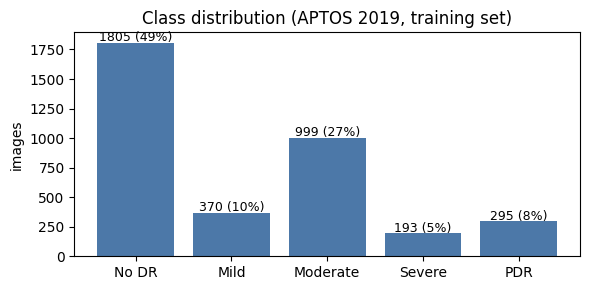

In [3]:
HF_REPO = "sngsfydy/aptos"
IMG_DIR = Path("/content/aptos512")              # local copy (fast); Drive only keeps a zipped cache
DRIVE_CACHE = WORK_DIR / "aptos512.zip"
MAX_SIDE = 512


def list_shards():
    with urllib.request.urlopen(f"https://huggingface.co/api/datasets/{HF_REPO}/tree/main/data") as r:
        return sorted(f["path"] for f in json.load(r) if f["path"].endswith(".parquet"))


def convert_shard(parquet_path, out_dir):
    # Save every image in one parquet shard as a <hash>.jpg (<= 512 px). Returns [(file name, grade), ...].
    rows = []
    pf = pq.ParquetFile(parquet_path)
    for group in range(pf.num_row_groups):
        table = pf.read_row_group(group).to_pydict()
        for img, label in zip(table["image"], table["label"]):
            raw = img["bytes"]
            name = hashlib.sha1(raw).hexdigest()[:16] + ".jpg"     # identical photos get identical names
            im = Image.open(io.BytesIO(raw)).convert("RGB")
            scale = MAX_SIDE / max(im.size)
            im.resize((round(im.width * scale), round(im.height * scale)), Image.LANCZOS).save(out_dir / name, quality=95)
            rows.append((name, int(label)))
    return rows


def download_aptos(out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for shard in list_shards():
        local = Path("/content") / Path(shard).name
        print("downloading", local.name, flush=True)
        subprocess.run(["curl", "-sSL", "--retry", "5", "-o", str(local),
                        f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{shard}"], check=True)
        rows += convert_shard(local, out_dir)
        local.unlink()                                             # free the disk before the next shard
        print(f"  {len(rows)} images so far", flush=True)
    pd.DataFrame(rows, columns=["id_code", "label"]).to_csv(out_dir / "labels.csv", index=False)


if not (IMG_DIR / "labels.csv").exists():
    if DRIVE_CACHE.exists():                                       # earlier session already did the download
        print("restoring cached images from Drive ...")
        subprocess.run(["unzip", "-q", "-o", str(DRIVE_CACHE), "-d", str(IMG_DIR)], check=True)
    else:
        download_aptos(IMG_DIR)
        print("saving a cache to Drive for next time ...")
        subprocess.run(["zip", "-q", "-r", "-j", str(DRIVE_CACHE), str(IMG_DIR)], check=True)

df = pd.read_csv(IMG_DIR / "labels.csv")
df["path"] = df["id_code"].map(lambda name: IMG_DIR / name)
print(f"{len(df)} images, {df['id_code'].nunique()} distinct files")

counts = df["label"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(CLASS_NAMES, counts.values, color="#4C78A8")
for i, c in enumerate(counts.values):
    ax.text(i, c + 15, f"{c} ({c / len(df):.0%})", ha="center", fontsize=9)
ax.set(title="Class distribution (APTOS 2019, training set)", ylabel="images")
plt.tight_layout(); plt.show()


### Data-quality check: duplicate images

Earlier work found that APTOS contains groups of **byte-identical images**, some with *conflicting* grades. On our run this check found **123 groups of identical images (3,662 images but only 3,534 distinct files), and in 30 of those groups the copies carry different grades.** Two consequences:

* a random split can put a copy of a test image into the training set (the cell after the split counts how often);
* contradictory labels are **label noise**: no model can be right on both copies. This is one plausible reason why very high accuracies are hard to reproduce on APTOS.

In [4]:
def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()

with ThreadPoolExecutor(os.cpu_count()) as pool:
    df["hash"] = list(tqdm(pool.map(file_hash, df["path"]), total=len(df), desc="hashing"))

groups = df.groupby("hash")["label"].agg(["size", "nunique"])
groups = groups[groups["size"] > 1]
print(f"{len(groups)} groups of identical images, {int((groups['nunique'] > 1).sum())} of them with conflicting grades")

123 groups of identical images, 30 of them with conflicting grades


## 5. Train / validation / test split

* **train (70%)**: the model learns from these.
* **validation (15%)**: used during training to monitor progress and to pick the "best" epoch.
* **test (15%, 550 images)**: never touched until the end. All reported numbers come from here.

`stratify` keeps the class proportions identical in all three parts, which matters because Severe and PDR are so rare (29 and 44 images in the test set). The seed makes the split repeatable. The paper does not state its APTOS split, so this is our assumption.

In [5]:
def make_split(df, seed=42, val_frac=0.15, test_frac=0.15):
    # Returns row positions (into df) for the train, val and test sets.
    positions = np.arange(len(df))
    train_val, test = train_test_split(positions, test_size=test_frac, stratify=df["label"], random_state=seed)
    train, val = train_test_split(train_val, test_size=val_frac / (1 - test_frac),
                                  stratify=df["label"].to_numpy()[train_val], random_state=seed)
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


labels = df["label"].to_numpy()
split = make_split(df, BASE_CFG.seed)
pd.DataFrame({name: np.bincount(labels[idx], minlength=NUM_CLASSES) for name, idx in split.items()},
             index=CLASS_NAMES)

,train,val,test
No DR,1263,271,271
Mild,258,56,56
Moderate,699,150,150
Severe,135,29,29
PDR,207,44,44


In [6]:
# How many test images have a byte-identical twin in the training set? (needs the hashes from the duplicate check)
if "hash" in df:
    train_hashes = set(df["hash"].to_numpy()[split["train"]])
    twin = np.array([h in train_hashes for h in df["hash"].to_numpy()[split["test"]]])
    print(f"{twin.sum()} of {len(twin)} test images ({twin.mean():.1%}) also appear, byte for byte, in the training set")
else:
    print("run the duplicate check above first")


29 of 550 test images (5.3%) also appear, byte for byte, in the training set


## 6. Pre-processing (once, up front)

The paper's recipe: boost local contrast with **CLAHE**, smooth with a small **Gaussian blur**, resize to a square.

* CLAHE is applied only to the *lightness* channel (LAB colour space), so colours are not distorted. It makes small lesions and vessels stand out.
* The raw photos are huge (up to 4000x3000), so each one is first shrunk to at most 512 px on the long side, which keeps CLAHE fast.
* The result is the same every epoch, so we compute it once for all images and keep them in memory (about 1 GB at 300x300).

**[not in paper] retina crop.** With `crop_retina=True` the black border around the eye is cut off first and the result is padded (with black) to a square, so the eye keeps its true shape instead of being squashed. The figure shows one example per grade: original (top), the paper's pre-processing (middle), with the crop (bottom).

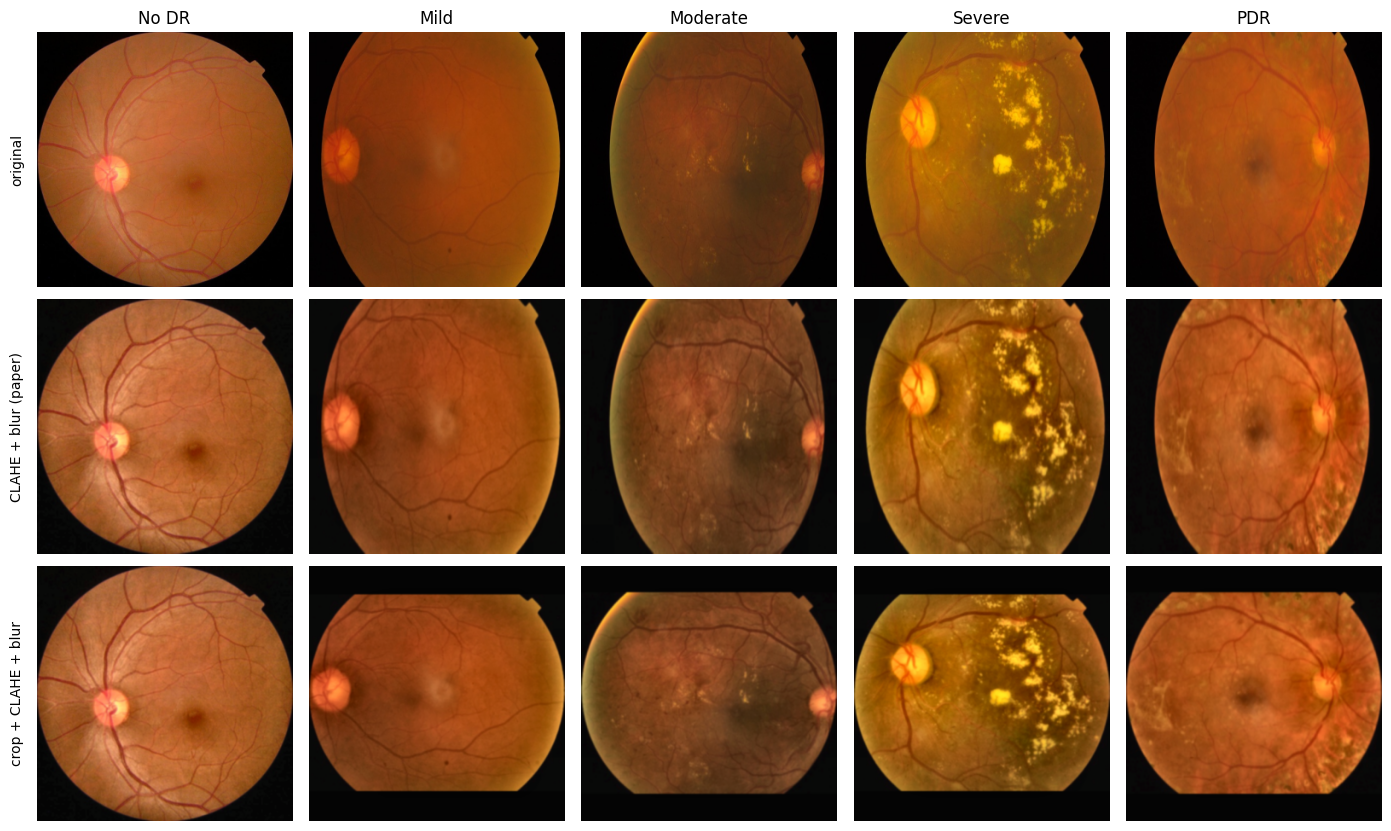

In [7]:
def crop_black_border(bgr, threshold=10):
    # Cut away the black margin around the retina. Very dark photos are left alone.
    mask = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY) > threshold
    if mask.mean() < 0.05:
        return bgr
    rows, cols = np.where(mask.any(1))[0], np.where(mask.any(0))[0]
    return bgr[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]


def pad_to_square(bgr):
    h, w = bgr.shape[:2]
    top, left = (max(h, w) - h) // 2, (max(h, w) - w) // 2
    return cv2.copyMakeBorder(bgr, top, max(h, w) - h - top, left, max(h, w) - w - left, cv2.BORDER_CONSTANT, value=0)


def preprocess(path, size, enhance=True, crop=False):
    # Load -> shrink -> [crop + square pad] -> (CLAHE + blur) -> square resize. Returns RGB uint8 (size, size, 3).
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    h, w = bgr.shape[:2]
    if max(h, w) > 512:
        scale = 512 / max(h, w)
        bgr = cv2.resize(bgr, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
    if crop:
        bgr = pad_to_square(crop_black_border(bgr))
    if enhance:
        lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
        lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
        bgr = cv2.GaussianBlur(cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), (5, 5), 0)
    bgr = cv2.resize(bgr, (size, size), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


# One example per grade: original (top), paper pre-processing (middle), with the retina crop (bottom).
examples = [df[df["label"] == c].iloc[0]["path"] for c in range(NUM_CLASSES)]
rows = [("original", dict(enhance=False)), ("CLAHE + blur (paper)", dict()), ("crop + CLAHE + blur", dict(crop=True))]
fig, axes = plt.subplots(len(rows), NUM_CLASSES, figsize=(14, 8.4))
for r, (title, kwargs) in enumerate(rows):
    for c, path in enumerate(examples):
        axes[r, c].imshow(preprocess(path, 300, **kwargs)); axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(CLASS_NAMES[c])
    axes[r, 0].text(-0.05, 0.5, title, transform=axes[r, 0].transAxes, rotation=90, ha="right", va="center")
plt.tight_layout(); plt.show()


In [8]:
_image_caches = {}


def get_images(size, crop):
    # Pre-processed images for one setting, built once (about 1 GB each at 300 px) and kept in memory.
    key = (size, crop)
    if key not in _image_caches:
        paths = df["path"].tolist()
        images = np.empty((len(paths), size, size, 3), dtype=np.uint8)

        def fill(i):
            images[i] = preprocess(paths[i], size, crop=crop)

        t0 = time.time()
        with ThreadPoolExecutor(os.cpu_count()) as pool:        # OpenCV releases the GIL, so threads are enough
            list(tqdm(pool.map(fill, range(len(paths))), total=len(paths), desc=f"pre-processing (crop={crop})"))
        print(f"{images.shape}, {images.nbytes / 1e9:.2f} GB, {time.time() - t0:.0f}s")
        _image_caches[key] = images
    return _image_caches[key]


for size, crop in sorted({(c.image_size, c.crop_retina) for c in EXPERIMENTS.values()}):
    get_images(size, crop)                                      # build everything needed up front
images = None                                                   # set by run_experiment for the current setting


(3662, 300, 300, 3), 0.99 GB, 38s


(3662, 300, 300, 3), 0.99 GB, 40s


## 7. Model

EfficientNet-B3 pretrained on ImageNet, with its original classifier removed and replaced by the paper's head:

```
1536 features -> Linear 512 -> Dropout 0.5 -> ReLU -> Linear 512 -> Dropout 0.25 -> ReLU -> Linear 5
```

**Transfer learning:** the backbone already knows generic visual features (edges, textures, shapes) from ImageNet. We keep them as a starting point and fine-tune **all layers** on retina images. Dropout randomly switches off units during training to reduce over-fitting. The paper trains with plain cross-entropy loss; `Config.loss="weighted_ce"` is the [not in paper] class-weighted variant of iteration 3.

In [9]:
class DRNet(nn.Module):
    def __init__(self, backbone="efficientnet_b3", pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0, global_pool="avg")
        self.head = nn.Sequential(
            nn.Linear(self.backbone.num_features, 512), nn.Dropout(0.5), nn.ReLU(inplace=True),
            nn.Linear(512, 512), nn.Dropout(0.25), nn.ReLU(inplace=True),
            nn.Linear(512, NUM_CLASSES),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


_mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
_std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)


def to_model_input(batch_uint8):
    # numpy (B, H, W, 3) uint8 -> normalised float tensor (B, 3, H, W) on the GPU.
    x = torch.from_numpy(batch_uint8).to(device).permute(0, 3, 1, 2).float() / 255.0
    return ((x - _mean) / _std).contiguous(memory_format=torch.channels_last)

## 8. Metrics and the snapshot ensemble

Besides QWK we report accuracy, macro-F1, macro AUC and **per-class recall** (the share of each grade that is found). Per-class recall matters here: a model can reach a decent QWK while never predicting a rare grade at all.

**Snapshot ensemble (paper, second strategy).** During training we save the model's predictions at 10 evenly spaced epochs (6, 12, ..., 60). The final grade is the *most common* prediction among those 10 (a majority vote); ties are broken by the average probability. This is cheaper than training 10 separate networks.

In [10]:
def compute_metrics(y_true, y_pred, probs):
    labels_all = list(range(NUM_CLASSES))
    prec, rec, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=labels_all, zero_division=0)
    return {
        "qwk": float(cohen_kappa_score(y_true, y_pred, weights="quadratic")),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_auc": float(roc_auc_score(y_true, probs, multi_class="ovr", average="macro")),
        "recall": {CLASS_NAMES[c]: float(rec[c]) for c in labels_all},
        "minority_recall": float(np.mean([rec[3], rec[4]])),       # mean recall of Severe and PDR
        "off_by_2_or_more": int(np.sum(np.abs(y_true - y_pred) >= 2)),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels_all).tolist(),
    }


def majority_vote(snapshot_probs):
    # snapshot_probs: (n_snapshots, n_images, 5) -> one predicted grade per image.
    votes = snapshot_probs.argmax(-1)                                          # each snapshot's vote
    tally = np.stack([(votes == c).sum(0) for c in range(NUM_CLASSES)], 1).astype(float)
    tally += 1e-3 * snapshot_probs.mean(0)                                     # tie-break
    return tally.argmax(1)

## 9. Training

Per epoch: one pass over the training set, then predict the validation set and log its QWK. We also store:

* **best-validation model**: test predictions from the epoch with the highest validation QWK (the usual "pick the best checkpoint" approach)
* **snapshots**: test predictions at the 10 evenly spaced epochs, for the ensemble

Nothing from the test set is used to make any decision. It is only predicted so we can report numbers at the end.
**[not in paper] augmentation.** With `augment=True` every training batch is randomly flipped and rotated. Validation and test images are never altered.

**[not in paper] class weights.** With `loss="weighted_ce"` each class gets the weight (1/frequency)^0.5, scaled so the average weight over the training set is 1. Rare grades count more in the loss, but less extremely than full inverse-frequency weights (which for Severe would be ~9x the No-DR weight and tend to destabilise training).

**[not in paper] cosine learning rate.** With `cosine_lr=True` the learning rate follows a half-cosine from its start value down to 1% of it over all epochs (stepped once per epoch).

**Safety net and logs.** The run can be stopped at any moment (Colab disconnect, closed tab, crash) without losing the work. After every epoch the notebook:

* appends the epoch to `runs/<name>/log.csv` in your Drive, so you can open it at any time to see progress
* saves a **checkpoint** `runs/<name>/last.pt` (model, optimizer, random state, log, snapshots, best-so-far), written atomically so a crash mid-save cannot corrupt it
* prints a status line: loss, validation QWK, best QWK so far, epoch time and estimated time left

To continue, just run the notebook again (**Runtime → Run all**). Finished experiments are loaded from Drive and skipped, and an unfinished one **resumes after its last completed epoch** (a half-finished epoch is redone, about 25 seconds of work). If you change a setting under an existing experiment name, the old files are ignored and that experiment starts fresh. `last.pt` is deleted when a run completes.

In [11]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def make_criterion(cfg):
    # Plain cross-entropy (paper), or [not in paper] cross-entropy with class weights ~ 1/sqrt(frequency).
    if cfg.loss == "ce":
        return nn.CrossEntropyLoss()
    if cfg.loss == "weighted_ce":
        counts = np.bincount(labels[split["train"]], minlength=NUM_CLASSES).astype(float)
        w = counts ** -0.5
        w = w / (w * counts).sum() * counts.sum()          # average weight over the training samples = 1
        print("  class weights:", {name: round(float(x), 2) for name, x in zip(CLASS_NAMES, w)})
        return nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device))
    raise ValueError(f"unknown loss {cfg.loss!r}")


def make_scheduler(optimizer, cfg):
    # [not in paper] half-cosine decay to 1% of the start lr; None keeps the lr constant (paper).
    if not cfg.cosine_lr:
        return None
    return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs, eta_min=cfg.lr * 0.01)


_black = -_mean / _std     # what a black pixel looks like after normalisation


def augment_batch(x):
    # [not in paper] Random horizontal flip + random rotation (0-360 degrees) for a normalised batch on the GPU.
    # Fundus photos have no natural "up", so any rotation is a valid new view. Empty corners stay black.
    n = x.shape[0]
    x = x - _black                                              # black -> 0 so rotation can pad with zeros
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(-1), x)
    angle = torch.rand(n, device=x.device) * 2 * math.pi
    cos, sin, zero = angle.cos(), angle.sin(), torch.zeros_like(angle)
    theta = torch.stack([torch.stack([cos, -sin, zero], 1), torch.stack([sin, cos, zero], 1)], 1)    # (n, 2, 3)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    return (x + _black).contiguous(memory_format=torch.channels_last)


@torch.no_grad()
def predict_probs(model, indices, cfg, batch_size=32):
    model.eval()
    out = []
    for start in range(0, len(indices), batch_size):
        x = to_model_input(images[indices[start:start + batch_size]])
        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            logits = model(x)
        out.append(torch.softmax(logits.float(), dim=1).cpu())
    return torch.cat(out).numpy()


def train_one_epoch(model, optimizer, scaler, criterion, cfg, rng):
    model.train()
    order = rng.permutation(split["train"])
    n_batches = len(order) // cfg.batch_size                                   # drop the last partial batch
    if cfg.max_train_batches:
        n_batches = min(n_batches, cfg.max_train_batches)
    total_loss, seen = 0.0, 0
    progress = tqdm(range(n_batches), desc="  training", leave=False)
    for b in progress:
        idx = np.sort(order[b * cfg.batch_size:(b + 1) * cfg.batch_size])      # sorted = faster memory reads
        x = to_model_input(images[idx])
        if cfg.augment:
            x = augment_batch(x)
        y = torch.from_numpy(labels[idx]).to(device)

        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            logits = model(x)
        loss = criterion(logits.float(), y)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                                             # so clipping sees real gradient sizes
        nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(y)
        seen += len(y)
        progress.set_postfix(loss=f"{total_loss / seen:.3f}")
    return total_loss / seen

In [12]:
def save_atomically(path, obj):
    # Write to a temp file, then rename: a crash mid-save can never leave a broken file behind.
    tmp = path.with_suffix(".tmp")
    try:
        torch.save(obj, tmp)
        tmp.replace(path)
    except (RuntimeError, OSError) as err:
        tmp.unlink(missing_ok=True)
        print(f"  warning: could not save {path.name} ({err})")


def run_experiment(name, cfg):
    # Train one configuration; return its training log, test predictions and metrics. Resumes if interrupted.
    global images
    run_dir = OUTPUT_DIR / "runs" / name
    run_dir.mkdir(parents=True, exist_ok=True)
    config_file, results_file = run_dir / "config.json", run_dir / "results.json"
    ckpt_path, best_path = run_dir / "last.pt", run_dir / "best_val_weights.pt"

    saved_cfg = json.loads(config_file.read_text()) if config_file.exists() else None
    if saved_cfg is not None:                 # files from before a setting existed: assume that setting's default
        saved_cfg = {**{f.name: f.default for f in fields(Config)}, **saved_cfg}
    same_config = saved_cfg == asdict(cfg)
    if not same_config:                       # a new experiment, or its settings changed: ignore any old files
        ckpt_path.unlink(missing_ok=True)
        results_file.unlink(missing_ok=True)
        config_file.write_text(json.dumps(asdict(cfg), indent=2))
    if results_file.exists():                 # finished in an earlier session
        print(f"\n=== {name} === already finished, loading saved results")
        return {"log": pd.read_csv(run_dir / "log.csv"), "config": cfg, "results": json.loads(results_file.read_text())}

    images = get_images(cfg.image_size, cfg.crop_retina)                       # the pre-processed images for this run
    print(f"\n=== {name} ===  lr={cfg.lr}  epochs={cfg.epochs}  batch={cfg.batch_size}  size={cfg.image_size}  "
          f"crop={cfg.crop_retina}  augment={cfg.augment}  loss={cfg.loss}  cosine={cfg.cosine_lr}")
    seed_everything(cfg.seed)
    model = DRNet(cfg.backbone, cfg.pretrained).to(device).to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp)
    scheduler = make_scheduler(optimizer, cfg)
    criterion = make_criterion(cfg)
    rng = np.random.default_rng(cfg.seed)

    snapshot_epochs = {round(cfg.epochs * k / cfg.n_snapshots) for k in range(1, cfg.n_snapshots + 1)}
    progress = {"log": [], "snapshot_test_probs": [], "best_val_qwk": -2.0, "best_epoch": 0, "best_test_probs": None}
    first_epoch = 1

    if ckpt_path.exists():                                                     # continue an interrupted run
        try:
            ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        except Exception as err:
            ckpt = None
            print(f"  could not read {ckpt_path.name} ({err}); starting from scratch")
        if ckpt is not None:
            model.load_state_dict(ckpt["model"])
            optimizer.load_state_dict(ckpt["optimizer"])
            scaler.load_state_dict(ckpt["scaler"])
            if scheduler is not None:
                scheduler.load_state_dict(ckpt["scheduler"])
            rng.bit_generator.state = ckpt["rng_numpy"]
            torch.set_rng_state(ckpt["rng_torch"])
            if ckpt["rng_cuda"] is not None:
                torch.cuda.set_rng_state_all(ckpt["rng_cuda"])
            progress, first_epoch = ckpt["progress"], ckpt["epoch"] + 1
            print(f"  RESUMED after epoch {ckpt['epoch']} (best so far: val QWK {progress['best_val_qwk']:.3f})")

    started, epochs_done_now = time.time(), 0
    for epoch in range(first_epoch, cfg.epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, optimizer, scaler, criterion, cfg, rng)

        val_probs = predict_probs(model, split["val"], cfg)
        val_pred = val_probs.argmax(1)
        val_qwk = float(cohen_kappa_score(labels[split["val"]], val_pred, weights="quadratic"))
        val_acc = float(accuracy_score(labels[split["val"]], val_pred))
        progress["log"].append({"epoch": epoch, "train_loss": train_loss, "val_qwk": val_qwk, "val_acc": val_acc})

        notes = ""
        if val_qwk > progress["best_val_qwk"]:                                 # new best on validation
            progress.update(best_val_qwk=val_qwk, best_epoch=epoch, best_test_probs=predict_probs(model, split["test"], cfg))
            save_atomically(best_path, model.state_dict())
            notes += " NEW BEST"
        if epoch in snapshot_epochs:                                           # ensemble member
            progress["snapshot_test_probs"].append(predict_probs(model, split["test"], cfg))
            notes += f" snapshot {len(progress['snapshot_test_probs'])}/{cfg.n_snapshots}"

        pd.DataFrame(progress["log"]).to_csv(run_dir / "log.csv", index=False)    # live log, readable at any time
        if scheduler is not None:
            scheduler.step()
        if epoch % CHECKPOINT_EVERY == 0 and epoch < cfg.epochs:
            save_atomically(ckpt_path, {
                "epoch": epoch, "progress": progress, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "scheduler": scheduler.state_dict() if scheduler else None,
                "rng_numpy": rng.bit_generator.state, "rng_torch": torch.get_rng_state(),
                "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None})

        epochs_done_now += 1
        eta_min = (time.time() - started) / epochs_done_now * (cfg.epochs - epoch) / 60
        print(f"[{name}] epoch {epoch:2d}/{cfg.epochs} | loss {train_loss:.3f} | val QWK {val_qwk:.3f} "
              f"(best {progress['best_val_qwk']:.3f} @ep{progress['best_epoch']}) | val acc {val_acc:.3f} | "
              f"{time.time() - t0:.0f}s | ~{eta_min:.0f} min left |{notes}")

    y_test = labels[split["test"]]
    snaps = np.stack(progress["snapshot_test_probs"])
    best_test_probs = progress["best_test_probs"]
    results = {
        "best_val_single": compute_metrics(y_test, best_test_probs.argmax(1), best_test_probs),
        "last_epoch_single": compute_metrics(y_test, snaps[-1].argmax(1), snaps[-1]),
        "snapshot_vote": compute_metrics(y_test, majority_vote(snaps), snaps.mean(0)),
        "snapshot_mean": compute_metrics(y_test, snaps.mean(0).argmax(1), snaps.mean(0)),
    }
    np.savez_compressed(run_dir / "test_probs.npz", best=best_test_probs, snapshots=snaps, y=y_test)
    results_file.write_text(json.dumps(results, indent=2))                     # written last = "this run is complete"
    ckpt_path.unlink(missing_ok=True)                                          # no longer needed
    return {"log": pd.DataFrame(progress["log"]), "results": results, "config": cfg}


## 10. Experiments

All six keep the paper's model, optimiser, batch size, 300 px, 60 epochs and 10-snapshot vote. Only the [not in paper] switches differ.

**Finished (run 2), loaded from Drive if present:**

| Experiment | lr | crop | aug | loss | cosine | question it answered |
|---|---|---|---|---|---|---|
| `1_crop_aug_lr1e-4` | 1e-4 | yes | yes | CE | no | how far do the first fixes get us? |
| `2_aug_lr1e-4` | 1e-4 | no | yes | CE | no | how much of that is the crop? (answer: none) |
| `3_crop_aug_lr1e-3` | 1e-3 | yes | yes | CE | no | does the paper's lr work with augmentation? (answer: no, unstable) |

**New (run 3), built on the best finished run `2_aug_lr1e-4`:**

| Experiment | loss | cosine | question it answers |
|---|---|---|---|
| `4_aug_lr1e-4_wce` | weighted CE | no | does weighting fix the rare grades (Severe, PDR, Mild)? |
| `5_aug_lr1e-4_cosine` | CE | yes | does a decaying learning rate calm the noisy epochs and improve the snapshot vote? |
| `6_aug_lr1e-4_wce_cosine` | weighted CE | yes | do the two help together? |

Each run takes about 25-35 minutes on a Colab T4, so the three new runs add roughly 1.5 hours. To save time you can delete experiments from the `EXPERIMENTS` dictionary in section 3.

**Stopped or disconnected?** Run the notebook again. Finished experiments are skipped and the unfinished one resumes (see section 7). Runs 1-2 were saved before the `loss` and `cosine_lr` settings existed; they are recognised as `loss="ce"`, `cosine_lr=False` and are **not** retrained.

**Outcome (details in section 12):** weighting raised Severe recall but not QWK; cosine decay did not help the ensemble; the combination was no better than either. None of the three beat `2_aug_lr1e-4`.


In [13]:
runs = {}
for name, cfg in EXPERIMENTS.items():
    runs[name] = run_experiment(name, cfg)

=== 1_crop_aug_lr1e-4 === already finished, loading saved results
=== 2_aug_lr1e-4 === already finished, loading saved results
=== 3_crop_aug_lr1e-3 === already finished, loading saved results
=== 4_aug_lr1e-4_wce ===  lr=0.0001  epochs=60  batch=16  size=300  crop=False  augment=True  loss=weighted_ce  cosine=False
  class weights: {'No DR': 0.69, 'Mild': 1.53, 'Moderate': 0.93, 'Severe': 2.12, 'PDR': 1.71}
[4_aug_lr1e-4_wce] epoch  1/60 | loss 1.167 | val QWK 0.800 (best 0.800 @ep1) | val acc 0.758 | 33s | ~33 min left | NEW BEST
[4_aug_lr1e-4_wce] epoch  2/60 | loss 0.787 | val QWK 0.879 (best 0.879 @ep2) | val acc 0.800 | 25s | ~28 min left | NEW BEST
[4_aug_lr1e-4_wce] epoch  3/60 | loss 0.693 | val QWK 0.865 (best 0.879 @ep2) | val acc 0.767 | 26s | ~27 min left |
[4_aug_lr1e-4_wce] epoch  4/60 | loss 0.613 | val QWK 0.897 (best 0.897 @ep4) | val acc 0.815 | 27s | ~26 min left | NEW BEST
[4_aug_lr1e-4_wce] epoch  5/60 | loss 0.593 | val QWK 0.900 (best 0.900 @ep5) | val acc 0.811

## 11. Results

All numbers are **test-set** results (550 images the model never saw or used for decisions). The table has one row per experiment and prediction type; the output covers all six experiments.

In [14]:
PAPER_QWK = 0.954        # reported by the paper for APTOS 2019 with ImageNet initialisation

PREDICTION_LABELS = {"best_val_single": "single model (best val epoch)", "last_epoch_single": "single model (last epoch)",
                     "snapshot_vote": "10-snapshot majority vote", "snapshot_mean": "10-snapshot mean probability"}
rows = []
for name, run in runs.items():
    for key, label in PREDICTION_LABELS.items():
        m = run["results"][key]
        rows.append({"experiment": name, "prediction": label, "QWK": m["qwk"], "accuracy": m["accuracy"],
                     "macro-F1": m["macro_f1"], "macro AUC": m["macro_auc"],
                     "Severe recall": m["recall"]["Severe"], "PDR recall": m["recall"]["PDR"],
                     "errors >= 2 grades": m["off_by_2_or_more"]})
summary = pd.DataFrame(rows)
summary.to_csv(OUTPUT_DIR / "summary.csv", index=False)
print(f"Paper reports QWK {PAPER_QWK} (APTOS 2019, ImageNet init).  Test set: {len(split['test'])} images.\n")
summary.style.format(precision=3).background_gradient(subset=["QWK"], cmap="Greens").hide(axis="index")

Paper reports QWK 0.954 (APTOS 2019, ImageNet init).  Test set: 550 images.



experiment,prediction,QWK,accuracy,macro-F1,macro AUC,Severe recall,PDR recall,errors >= 2 grades
1_crop_aug_lr1e-4,single model (best val epoch),0.883,0.800,0.620,0.917,0.241,0.523,21
1_crop_aug_lr1e-4,single model (last epoch),0.878,0.789,0.589,0.903,0.310,0.591,29
1_crop_aug_lr1e-4,10-snapshot majority vote,0.893,0.816,0.635,0.934,0.241,0.568,22
1_crop_aug_lr1e-4,10-snapshot mean probability,0.894,0.820,0.640,0.934,0.241,0.568,22
2_aug_lr1e-4,single model (best val epoch),0.908,0.831,0.684,0.933,0.345,0.682,21
2_aug_lr1e-4,single model (last epoch),0.881,0.813,0.630,0.919,0.310,0.545,28
2_aug_lr1e-4,10-snapshot majority vote,0.898,0.829,0.653,0.940,0.276,0.591,22
2_aug_lr1e-4,10-snapshot mean probability,0.898,0.831,0.655,0.940,0.276,0.591,22
3_crop_aug_lr1e-3,single model (best val epoch),0.838,0.785,0.507,0.916,0.000,0.364,35
3_crop_aug_lr1e-3,single model (last epoch),0.839,0.775,0.465,0.920,0.000,0.227,39


### How much can we trust the differences? (bootstrap confidence intervals)

The test set has only 550 images, and the rare grades have 29 and 44 of them. A different random sample of 550 patients would give a somewhat different QWK. To measure that, we **resample the test set with replacement 2,000 times**, recompute QWK each time, and report the middle 95% of the values. **If two experiments' intervals overlap heavily, we cannot claim that one is better** (the same predictions are re-used, so this measures test-set noise only, not training randomness: each experiment was trained once with one seed).

In [15]:
def bootstrap_qwk(y, pred, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        scores.append(cohen_kappa_score(y[idx], pred[idx], weights="quadratic"))
    return np.percentile(scores, [2.5, 50, 97.5])


ci_rows = []
for name in runs:
    data = np.load(OUTPUT_DIR / "runs" / name / "test_probs.npz")
    y = data["y"]
    for label, pred in [("single model (best val epoch)", data["best"].argmax(1)),
                        ("10-snapshot majority vote", majority_vote(data["snapshots"]))]:
        lo, mid, hi = bootstrap_qwk(y, pred)
        ci_rows.append({"experiment": name, "prediction": label,
                        "QWK": cohen_kappa_score(y, pred, weights="quadratic"), "95% CI low": lo, "95% CI high": hi})
ci_table = pd.DataFrame(ci_rows)
ci_table.to_csv(OUTPUT_DIR / "qwk_confidence_intervals.csv", index=False)
ci_table.style.format(precision=3).hide(axis="index")


experiment,prediction,QWK,95% CI low,95% CI high
1_crop_aug_lr1e-4,single model (best val epoch),0.883,0.851,0.909
1_crop_aug_lr1e-4,10-snapshot majority vote,0.893,0.862,0.918
2_aug_lr1e-4,single model (best val epoch),0.908,0.882,0.930
2_aug_lr1e-4,10-snapshot majority vote,0.898,0.868,0.921
3_crop_aug_lr1e-3,single model (best val epoch),0.838,0.799,0.872
3_crop_aug_lr1e-3,10-snapshot majority vote,0.831,0.805,0.856
4_aug_lr1e-4_wce,single model (best val epoch),0.878,0.841,0.907
4_aug_lr1e-4_wce,10-snapshot majority vote,0.897,0.867,0.921
5_aug_lr1e-4_cosine,single model (best val epoch),0.906,0.880,0.928
5_aug_lr1e-4_cosine,10-snapshot majority vote,0.883,0.848,0.909


### Training curves

Blue: validation QWK. Orange: validation accuracy. Dashed grey: training loss (right axis). A falling training loss with a flat validation curve means **over-fitting**. (Top row: experiments 1-3, from the iteration-2 run. Bottom row: experiments 4-6.) A validation curve that swings wildly or drops to zero means the **learning rate is too high** (compare lr 1e-3 with lr 1e-4).

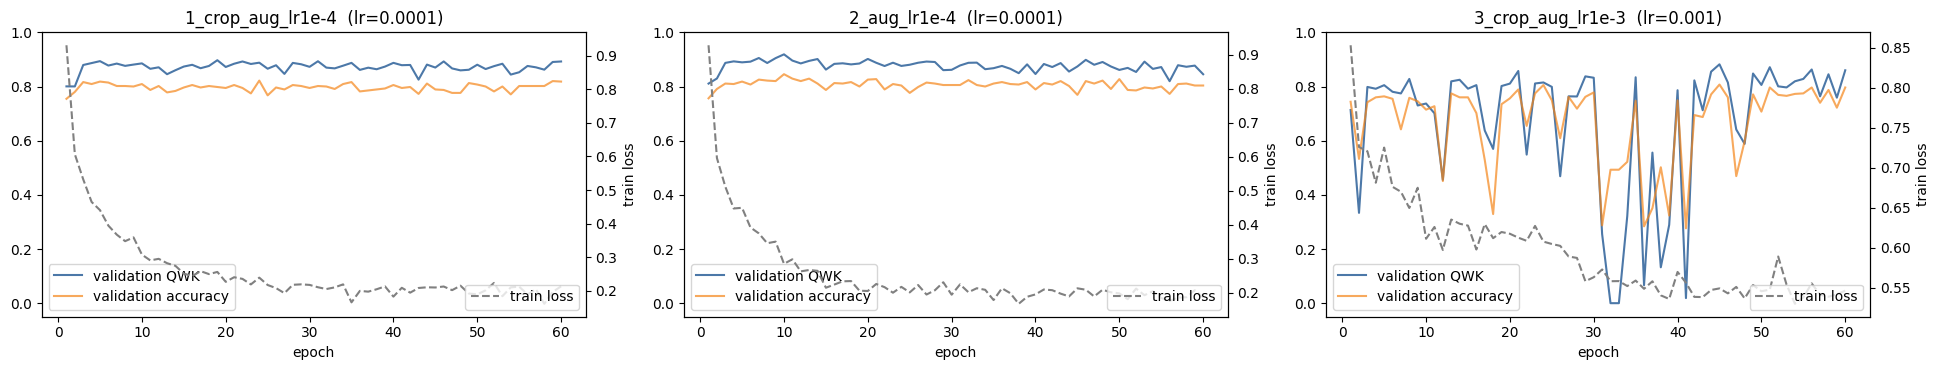

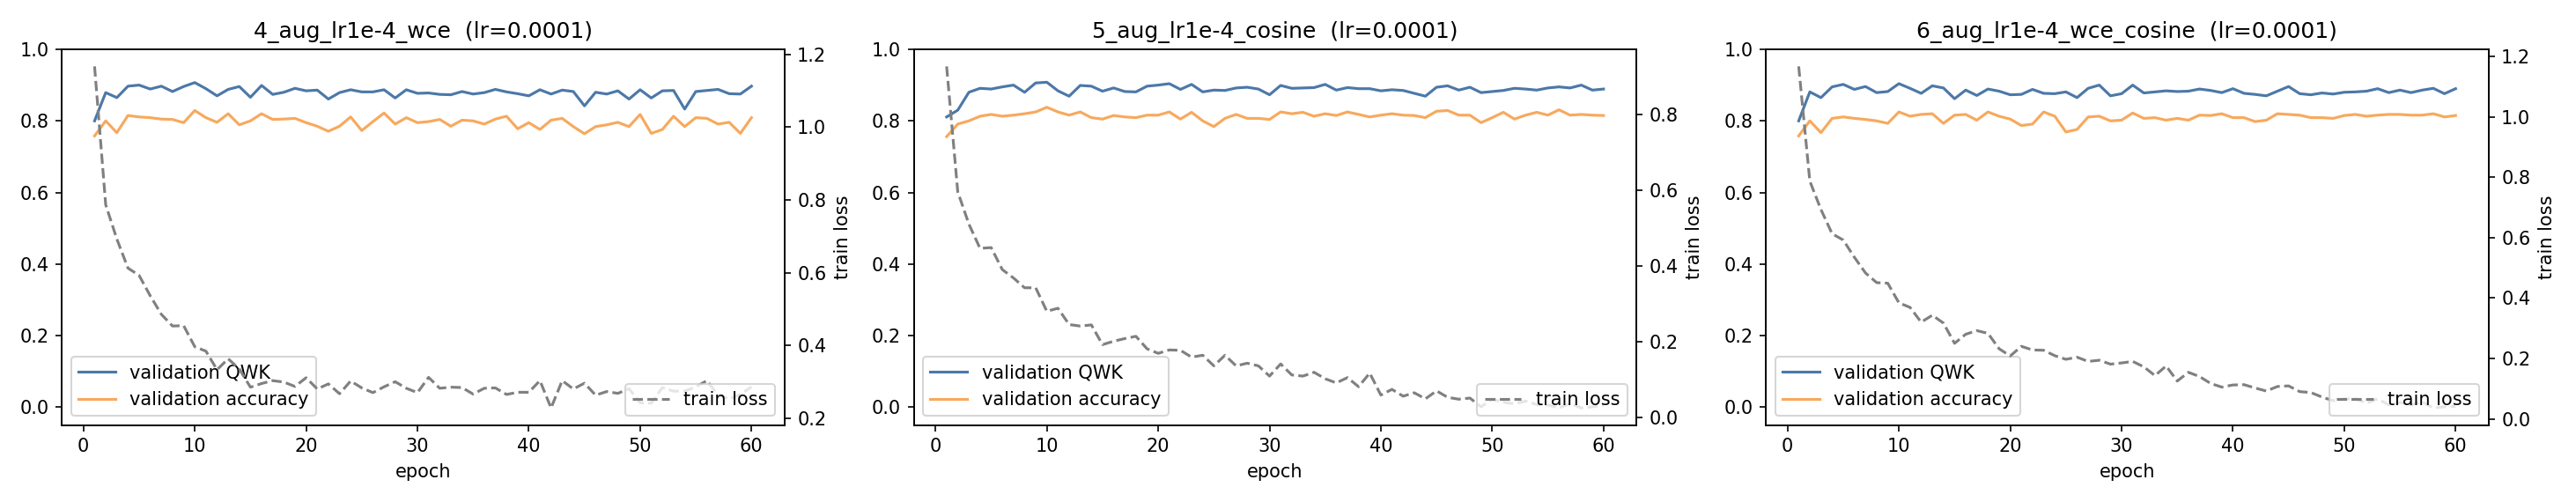

In [15]:
ncols = min(3, len(runs)); nrows = math.ceil(len(runs) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 3.8 * nrows), squeeze=False)
for ax in axes.flat[len(runs):]:
    ax.axis("off")
for ax, (name, run) in zip(axes.flat, runs.items()):
    log = run["log"]
    ax.plot(log["epoch"], log["val_qwk"], label="validation QWK", color="#4C78A8")
    ax.plot(log["epoch"], log["val_acc"], label="validation accuracy", color="#F58518", alpha=0.7)
    ax.set(title=f"{name}  (lr={run['config'].lr})", xlabel="epoch", ylim=(-0.05, 1.0))
    twin = ax.twinx()
    twin.plot(log["epoch"], log["train_loss"], color="gray", linestyle="--", label="train loss")
    twin.set_ylabel("train loss")
    ax.legend(loc="lower left"); twin.legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150); plt.show()


### Confusion matrices (test set)

Rows are the true grade, columns the predicted grade. Numbers on the diagonal are correct. Look at the **Severe** row: if its diagonal cell is empty, the model has learned to never predict that grade, even when QWK still looks good.

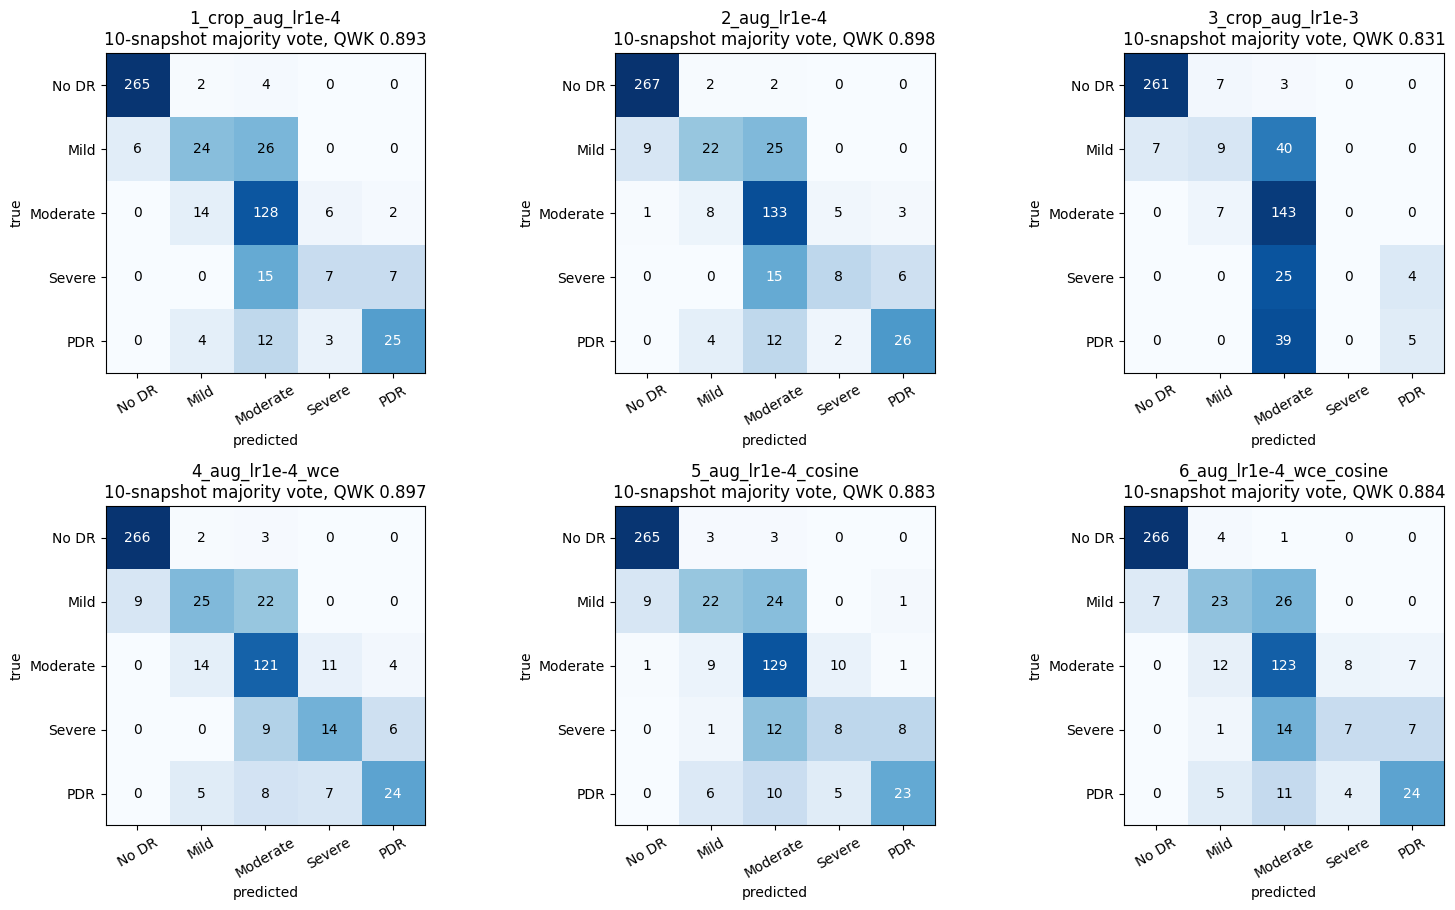

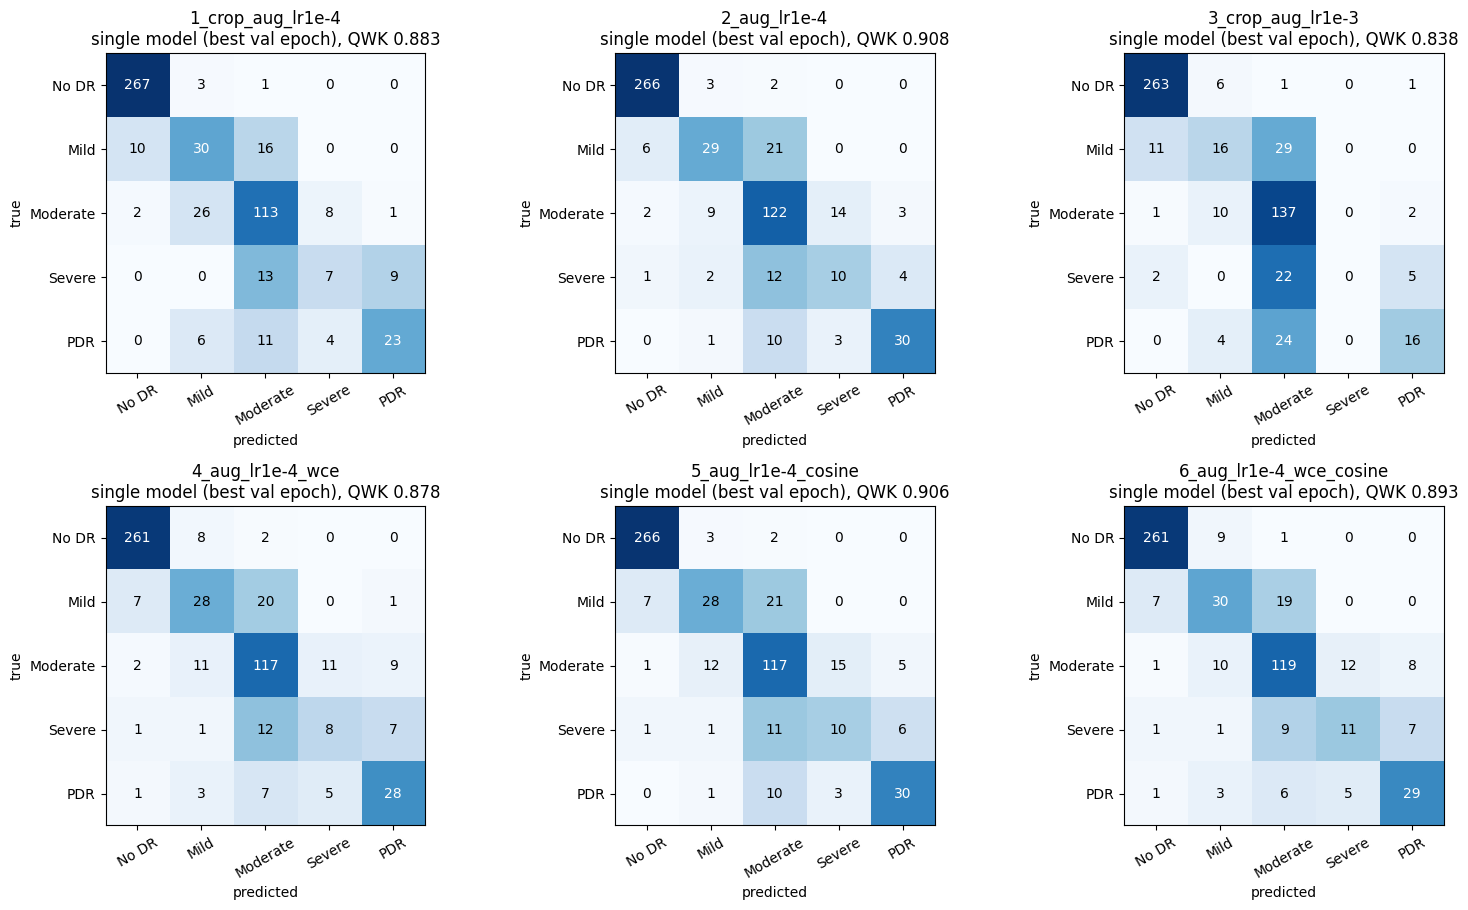

In [17]:
for key in ["snapshot_vote", "best_val_single"]:
    ncols = min(3, len(runs)); nrows = math.ceil(len(runs) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.6 * nrows), squeeze=False)
    for ax in axes.flat[len(runs):]:
        ax.axis("off")
    for ax, (name, run) in zip(axes.flat, runs.items()):
        m = run["results"][key]
        cm = np.array(m["confusion_matrix"])
        ax.imshow(cm / cm.sum(1, keepdims=True).clip(1), cmap="Blues", vmin=0, vmax=1)    # shading = per-row share
        for r in range(NUM_CLASSES):
            for c in range(NUM_CLASSES):
                ax.text(c, r, cm[r, c], ha="center", va="center",
                        color="white" if cm[r, c] / max(cm[r].sum(), 1) > 0.5 else "black")
        ax.set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES), xlabel="predicted", ylabel="true",
               title=f"{name}\n{PREDICTION_LABELS[key]}, QWK {m['qwk']:.3f}")
        ax.set_xticklabels(CLASS_NAMES, rotation=30); ax.set_yticklabels(CLASS_NAMES)
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / f"confusion_matrices_{key}.png", dpi=150); plt.show()


## 12. Discussion

**What the evidence says (iteration 2, test set of 550 images).**

| Question | Evidence | Answer |
|---|---|---|
| Did augmentation + lower lr help? | vote 0.884 -> 0.898, single model 0.846 -> 0.908 | **Yes, modestly.** Best result so far. |
| Did the retina crop help? | 0.893 vs 0.898 (vote), 0.883 vs 0.908 (single) | **No measurable benefit.** The difference is within test-set noise, so later experiments leave it off. |
| Does the paper's lr 1e-3 work? | validation QWK collapses repeatedly (down to 0.07); Severe never predicted; vote 0.831 | **No**, even with augmentation. Fine-tuning all layers with Adam at 1e-3 is too aggressive here. |
| Is over-fitting solved? | training loss ends near 0.2 (was 0.12), validation QWK still flat after epoch ~10 | **Reduced, not removed.** |
| Does the ensemble help? | vote > single model in some runs, < in others | **Inconsistent**: it helps when late snapshots are good, and hurts at lr 1e-3 because it averages collapsed epochs. |

**Where the errors are.** For the best run (`2_aug_lr1e-4`, vote): No DR 267/271 correct and Moderate 133/150, but **Mild only 22/56, Severe 8/29, PDR 26/44**. Severe cases are mostly called Moderate (15 of 29), and Mild cases are mostly called Moderate (25 of 56). Only about 4% of test images are off by two or more grades. The **macro AUC is high (0.93-0.94)** while macro-F1 is only about 0.65: the network *ranks* severity well, but with plain cross-entropy and rare classes its arg-max decision rarely picks the rare grades. This is why iteration 3 changes the loss and the schedule rather than the architecture.

**Why not 0.954?** We cannot say for certain. Differences we know of: the paper does not state its APTOS split, batch size or CLAHE settings, so ours are assumptions; its 0.942 accuracy is far above the 0.80-0.83 we obtain on a clean hold-out; APTOS contains duplicates with conflicting grades (label noise); and a different split can change QWK noticeably on a 550-image test set. We do not claim the paper's number is wrong, only that we could not reproduce it.

**Iteration 3: hypotheses (written before running) and outcome.**

| Experiment (all on top of `2_aug_lr1e-4`) | QWK single / vote (vote 95% CI) | Severe recall (vote) | PDR recall | errors off by >= 2 grades | verdict |
|---|---|---|---|---|---|
| `2_aug_lr1e-4` (reference) | 0.908 / 0.898 (0.868-0.921) | 28% (8/29) | 59% | 22 | |
| `4_..._wce` (weighted loss) | 0.878 / 0.897 (0.867-0.921) | **48% (14/29)** | 55% | 20 | rare-grade recall up, QWK unchanged |
| `5_..._cosine` | 0.906 / 0.883 (0.848-0.909) | 28% | 52% | 23 | ensemble slightly worse |
| `6_..._wce_cosine` | 0.893 / 0.884 (0.852-0.909) | 24% | 55% | 25 | no combined gain |

1. *Hypothesis: class weights raise Severe/PDR/Mild recall and move cases out of the Moderate column.* **Partly confirmed.** Severe recall rose from 8/29 to 14/29 and Mild from 22 to 25 of 56, but Moderate recall fell from 133 to 121 of 150 (6 more Moderate cases were called Mild, 6 more Severe and 1 more PDR) and PDR recall fell slightly (26 -> 24 of 44). QWK is a single number that rewards near-misses, so trading Moderate accuracy for Severe recall nets out at the same 0.897. This is a **clinical trade-off, not a free improvement**: in screening, missing a Severe case is usually worse than over-referring a Moderate one, so the weighted model can be the better choice even though its QWK is not higher.
2. *Hypothesis: cosine decay calms the late epochs and improves the snapshot vote.* **Rejected.** The ensemble got worse (0.898 -> 0.883). With the learning rate shrinking towards zero the training loss falls to 0.03 (it stays near 0.2 without decay), meaning the network memorises the training set, and the late snapshots become near-copies of each other, so voting adds nothing. This is our interpretation of the curves, not something we tested separately. Validation QWK in the cosine run still peaked around epoch 10 (0.908), as in the other runs.
3. *Hypothesis: both together may help.* **Rejected**, 0.884: the gains did not add up.

**The pattern across all runs.** Every lr 1e-4 run reaches its best validation QWK (about 0.90-0.91) within the first 10-20 epochs and does not improve afterwards. With these settings the plateau is about **0.88-0.91 QWK**. The 95% intervals of all five lr 1e-4 experiments overlap (each is about +/-0.03 wide), so **we cannot rank them statistically**. The clear effects are: lr 1e-3 is worse (vote 0.831, interval 0.805-0.856), and **the paper's 0.954 lies above every interval** (the highest upper bound is 0.930), so the gap to the paper is larger than test-set sampling noise on our split.

## 13. Limitations

* **One training run per setting (one random seed).** The confidence intervals in section 11 measure only test-set sampling noise, not training randomness. Differences below about 0.02 QWK should not be treated as real.
* **Small test set.** 550 images, only 29 Severe and 44 PDR, so recall on those grades is very uncertain.
* **The validation set picks the best epoch** from 60 noisy values, so the "single model (best val)" number is mildly optimistic compared with the ensemble, which uses no selection.
* **Assumed settings** (split, batch size, CLAHE parameters, 512 px pre-shrink) differ from whatever the authors used.
* **Data quality.** Duplicates and contradictory labels limit the achievable accuracy, and **29 of the 550 test images (5.3%) have a byte-identical twin in the training set**, which makes our scores, if anything, slightly optimistic. We did not measure by how much.
* **No external validation** (other datasets or hospitals) and **no EyePACS pre-training**, so the paper's best result (0.967) is out of scope.
* This is a **reproduction study, not a clinical tool**.

## 14. Conclusion and next steps

1. Re-implementing the paper from its text gave **QWK 0.81-0.88** on a stratified held-out test set, below the published 0.954.
2. Evidence-driven changes (augmentation, lr 1e-4) improved this to **about 0.90-0.91**. The retina crop and cosine decay did not help, lr 1e-3 is unstable, and class weights traded Moderate accuracy for Severe recall without changing QWK.
3. The plateau around 0.90 is **not a tuning problem we could fix with small changes**: five different lr 1e-4 variants are statistically tied, and even the best interval (up to 0.930) stays below 0.954. Plausible reasons are an unknown split, label noise from conflicting duplicates, and settings the paper does not state.
4. The main remaining weakness is the **rare grades** (Severe recall 28-48%, PDR 52-59%).
5. **Next (Stage 4), if continued:** an ordinal-aware loss or regression head (grades are ordered and QWK rewards near-misses), several random seeds to measure training variance, de-duplicating the data before splitting, and optionally EyePACS pre-training. `make_criterion` in section 9 is the single function to extend.

---

## Appendix A: how to run

1. Open [colab.research.google.com](https://colab.research.google.com) -> **File -> Upload notebook** and pick this `.ipynb`.
2. **Runtime -> Change runtime type -> T4 GPU -> Save.**
3. **Runtime -> Run all.** Colab asks once to connect Google Drive: click *Connect*.
4. The first run downloads APTOS (about 9 GB, ~15 minutes), shrinks the images (~160 MB) and caches them in Drive. Each experiment takes about 25-35 minutes on a T4.

**If Colab disconnects:** nothing finished is lost. The data cache, every finished experiment and a resumable checkpoint of the running experiment are in `MyDrive/dr-grading/`. Open the notebook again and choose **Run all**; it continues after the last completed epoch. Set `QUICK_TEST = True` first for a two-minute check.

## Appendix B: glossary

| Term | Meaning |
|---|---|
| **Fundus photo** | photograph of the back of the eye (retina) |
| **QWK** | quadratic weighted kappa: agreement between predicted and true grade, corrected for chance, with far-off mistakes penalised quadratically |
| **CLAHE** | contrast-limited adaptive histogram equalisation: boosts local contrast in small tiles without amplifying noise |
| **Transfer learning / fine-tuning** | start from a network pretrained on a large dataset (ImageNet) and keep training it on our data |
| **Over-fitting** | the model memorises the training images (training loss keeps falling) without getting better on new images (validation score stays flat) |
| **Data augmentation** | showing the network randomly flipped / rotated versions of the training images so it cannot memorise them |
| **Snapshot ensemble** | predictions from several moments of one training run, combined by vote |
| **Recall (per class)** | of all images with a given true grade, the share the model labels correctly |
| **Confusion matrix** | table of true grade (rows) against predicted grade (columns) |
| **Class-weighted cross-entropy** | the loss counts mistakes on rare classes more heavily |
| **Cosine learning-rate decay** | the learning rate shrinks smoothly during training |
| **Bootstrap confidence interval** | spread of a metric when the test set is resampled many times: shows how much it depends on which images were drawn |

## Appendix C: files written to Google Drive

Under `MyDrive/dr-grading/outputs/`: `summary.csv`, `qwk_confidence_intervals.csv`, `training_curves.png`, `confusion_matrices_snapshot_vote.png`, `confusion_matrices_best_val_single.png`, and per run `runs/<name>/{config.json, results.json, log.csv, test_probs.npz, best_val_weights.pt}` (plus `last.pt` while a run is in progress).

## Appendix D: reference

Chilukoti, S. V., Shan, L., Tida, V. S., Maida, A. S., Hei, X. (2024). *A reliable diabetic retinopathy grading via transfer learning and ensemble learning with quadratic weighted kappa metric.* BMC Medical Informatics and Decision Making, 24:37.